# EDA

Requiere haber corrido `descarga.ipynb` antes (dataset ya en `data/`). Este notebook:

1. Parsea todos los `.txt` de labels a un DataFrame: `imagen, split, clase, area_relativa, aspect_ratio`.
2. Tabla de composición por categoría (solo fuego / solo humo / ambos / none) por split.
3. Histograma de área relativa por clase — evidencia para **H1** (el fuego incipiente ocupa pocos píxeles).
4. Distribución de cajas por imagen.
5. Conteo de negativos por split.

In [2]:
from pathlib import Path
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt

IMAGE_EXTS = {".jpg", ".jpeg", ".png"}
REPO_ROOT = Path.cwd()
DATA_DIR = REPO_ROOT / "data"

## 0. Orden de clases

Completar según lo verificado en `descarga.ipynb` (sección 6) leyendo labels reales — **no asumir**.

In [3]:
CLASS_NAMES = {
    0: "smoke",
    1: "fire",
}

## 1. Ubicar splits

Misma detección automática que en `descarga.ipynb`, corrida sobre `data/` (el dataset ya descargado).

In [4]:
def find_split_dirs(root: Path):
    candidates = {"train": [], "val": [], "valid": [], "test": []}
    for p in root.rglob("*"):
        if p.is_dir() and p.name.lower() in candidates:
            candidates[p.name.lower()].append(p)
    return candidates

split_candidates = find_split_dirs(DATA_DIR)
SPLIT_DIRS = {
    "train": split_candidates["train"][0] if split_candidates["train"] else None,
    "val": (split_candidates["val"] or split_candidates["valid"] or [None])[0],
    "test": split_candidates["test"][0] if split_candidates["test"] else None,
}
SPLIT_DIRS

{'train': WindowsPath('c:/Proyectos/CV2/detección_incendios/data/data/train'),
 'val': WindowsPath('c:/Proyectos/CV2/detección_incendios/data/data/val'),
 'test': WindowsPath('c:/Proyectos/CV2/detección_incendios/data/data/test')}

## 2. Parseo de labels a DataFrame

Una fila por bounding box (`imagen, split, clase, area_relativa, aspect_ratio`). Las imágenes sin objetos ("none") quedan con una única fila con `clase=None`.

In [5]:
def parse_split(split: str, split_dir: Path) -> list[dict]:
    images = sorted(p for p in split_dir.rglob("*") if p.suffix.lower() in IMAGE_EXTS)
    label_index = {p.stem: p for p in split_dir.rglob("*.txt")}

    rows = []
    for img_path in images:
        label_path = label_index.get(img_path.stem)
        text = label_path.read_text().strip() if label_path is not None else ""

        if not text:
            rows.append({
                "imagen": img_path.name,
                "split": split,
                "clase": None,
                "area_relativa": None,
                "aspect_ratio": None,
            })
            continue

        for line in text.splitlines():
            cls_idx, _, _, w, h = (float(x) for x in line.split()[:5])
            cls_idx = int(cls_idx)
            rows.append({
                "imagen": img_path.name,
                "split": split,
                "clase": CLASS_NAMES.get(cls_idx, cls_idx),
                "area_relativa": w * h,
                "aspect_ratio": (w / h) if h > 0 else None,
            })
    return rows

all_rows = []
for split, split_dir in SPLIT_DIRS.items():
    if split_dir is None:
        print(f"[!] No se encontró carpeta para split '{split}'")
        continue
    all_rows.extend(parse_split(split, split_dir))

df = pd.DataFrame(all_rows)
df.head()

,imagen,split,clase,area_relativa,aspect_ratio
0,AoF00000.jpg,train,NaN,NaN,NaN
1,AoF00001.jpg,train,fire,0.020604,0.909620
2,AoF00002.jpg,train,smoke,0.002011,0.673525
3,AoF00003.jpg,train,NaN,NaN,NaN
4,AoF00004.jpg,train,NaN,NaN,NaN


## 3. Composición por categoría y split

Por imagen: `solo_fuego`, `solo_humo`, `ambos` o `none`, según el conjunto de clases presentes.

In [6]:
def categorize(classes: set) -> str:
    classes = classes - {None}
    if not classes:
        return "none"
    if classes == {"fire"}:
        return "solo_fuego"
    if classes == {"smoke"}:
        return "solo_humo"
    return "ambos"

img_category = (
    df.groupby(["split", "imagen"])["clase"]
    .apply(lambda s: categorize(set(s)))
    .rename("categoria")
    .reset_index()
)

composition = (
    img_category.groupby(["split", "categoria"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=["solo_fuego", "solo_humo", "ambos", "none"])
)
composition["total"] = composition.sum(axis=1)
composition.loc["total"] = composition.sum()
composition

categoria,solo_fuego,solo_humo,ambos,none,total
split,,,,,
test,220.0,1186.0,2900.0,NaN,4306.0
train,770.0,3836.0,9516.0,NaN,14122.0
val,174.0,845.0,2080.0,NaN,3099.0
total,1164.0,5867.0,14496.0,0.0,21527.0


## 4. Área relativa por clase, evidencia H1

H1: el fuego incipiente ocupa pocos píxeles; se espera que `fire` concentre más masa en áreas relativas chicas que `smoke`.

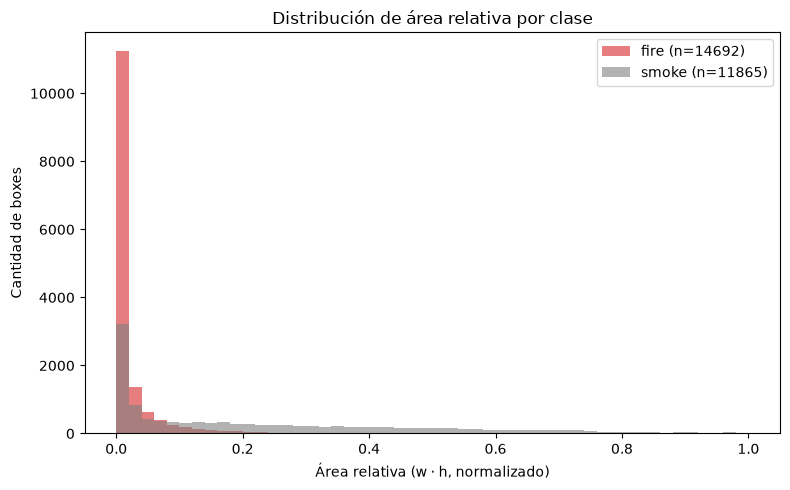

In [7]:
boxes = df.dropna(subset=["clase"])

fig, ax = plt.subplots(figsize=(8, 5))
for clase, color in (("fire", "tab:red"), ("smoke", "tab:gray")):
    subset = boxes.loc[boxes["clase"] == clase, "area_relativa"]
    ax.hist(subset, bins=50, range=(0, 1), alpha=0.6, label=f"{clase} (n={len(subset)})", color=color)

ax.set_xlabel("Área relativa (w · h, normalizado)")
ax.set_ylabel("Cantidad de boxes")
ax.set_title("Distribución de área relativa por clase")
ax.legend()
fig.tight_layout()

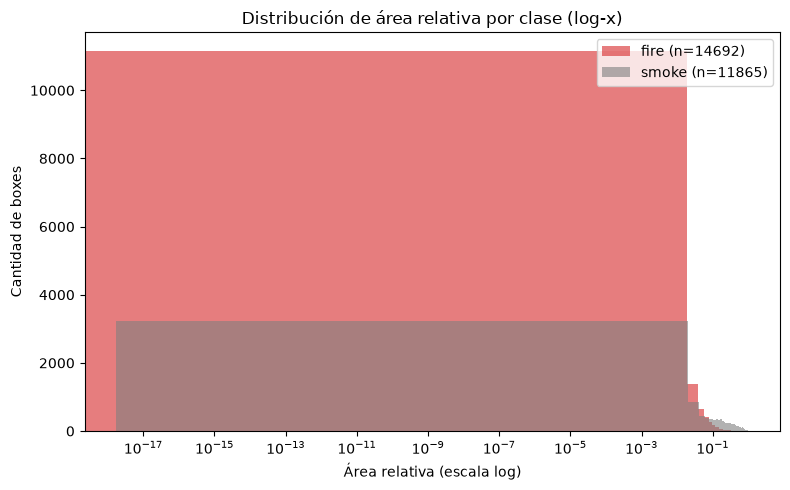

In [8]:
# Misma distribución en escala log, para ver mejor la cola de objetos chicos
fig, ax = plt.subplots(figsize=(8, 5))
for clase, color in (("fire", "tab:red"), ("smoke", "tab:gray")):
    subset = boxes.loc[boxes["clase"] == clase, "area_relativa"]
    ax.hist(subset, bins=50, alpha=0.6, label=f"{clase} (n={len(subset)})", color=color)

ax.set_xscale("log")
ax.set_xlabel("Área relativa (escala log)")
ax.set_ylabel("Cantidad de boxes")
ax.set_title("Distribución de área relativa por clase (log-x)")
ax.legend()
fig.tight_layout()

## 5. Distribución de cajas por imagen

count    11689.000000
mean         2.271965
std          1.959384
min          1.000000
25%          1.000000
50%          1.000000
75%          3.000000
max         23.000000
Name: n_boxes, dtype: float64

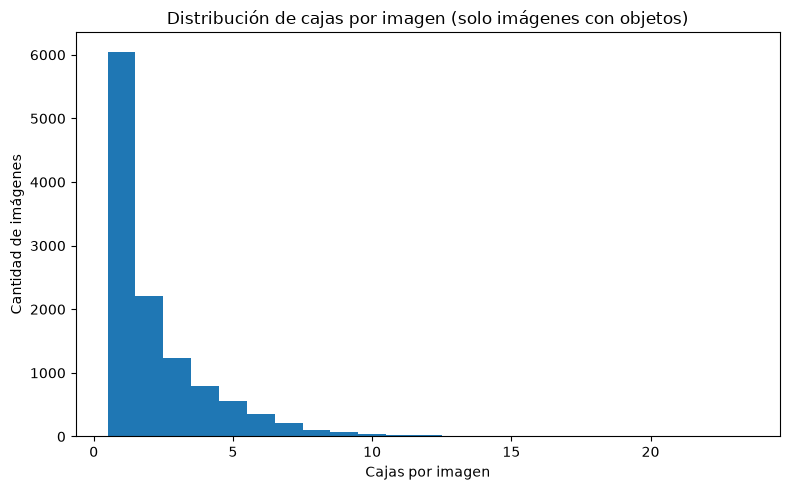

In [9]:
boxes_per_image = (
    boxes.groupby(["split", "imagen"]).size().rename("n_boxes").reset_index()
)

fig, ax = plt.subplots(figsize=(8, 5))
max_boxes = int(boxes_per_image["n_boxes"].max())
ax.hist(
    boxes_per_image["n_boxes"],
    bins=range(1, max_boxes + 2),
    align="left",
    color="tab:blue",
)
ax.set_xlabel("Cajas por imagen")
ax.set_ylabel("Cantidad de imágenes")
ax.set_title("Distribución de cajas por imagen (solo imágenes con objetos)")
fig.tight_layout()

boxes_per_image["n_boxes"].describe()

## 6. Conteo de negativos por split

In [10]:
negatives = (
    img_category[img_category["categoria"] == "none"]
    .groupby("split")
    .size()
    .rename("n_negativos")
)
totals = img_category.groupby("split").size().rename("n_total")

neg_table = pd.concat([negatives, totals], axis=1).fillna(0)
neg_table["pct_negativos"] = (neg_table["n_negativos"] / neg_table["n_total"] * 100).round(1)
neg_table

,n_negativos,n_total,pct_negativos
split,,,
test,0.0,4306,0.0
train,0.0,14122,0.0
val,0.0,3099,0.0
